# MedVision Smart — Segmentation biomédicale intelligente
## Étape 1 · Notebook 04 : Évaluation finale sur le test, comparaison et analyse d'erreurs

**Équipe :** Abderrahman Ghazouani · Hiba Hamrani · Anas Latifi

---

### Où en est-on ?

| Notebook | Contenu | Auteur |
|---|---|---|
| 01_exploration | Nettoyage, quasi-doublons, découpage **par groupe** → `splits.csv` (537 / 114 / 111) | Abderrahman |
| 02_baselines | Otsu + CNN simple, métriques communes dans `utils.py` | Hiba |
| 03_unet_unetpp | U-Net et U-Net++, réglage perte × learning rate × taille | Anas |
| **04_evaluation** (ce notebook) | **Évaluation finale sur le test**, tableau comparatif, analyse d'erreurs, choix du modèle | Équipe |

### Le principe de ce notebook

Jusqu'ici, **toutes les décisions** (hyperparamètres, choix du meilleur réglage de chaque algorithme) ont été prises sur la **validation**. Le **test** (111 images) n'a jamais été utilisé.

Ce notebook :
1. **reprend** la meilleure configuration de chaque algorithme, telle qu'elle a été choisie sur la validation ;
2. **vérifie** que les modèles rechargés redonnent bien leurs scores de validation (contrôle de cohérence) ;
3. évalue les 4 algorithmes **une seule fois** sur le test ;
4. compare, mesure l'incertitude, et **analyse les erreurs**.

⚠️ **Règle :** on ne revient **jamais** modifier un modèle ou un réglage après avoir vu les scores du test. Sinon, le test deviendrait une deuxième validation et ses scores seraient trop optimistes.

### Plan

0. Préparation
1. Les configurations retenues sur la validation
2. Chargement des modèles
3. Contrôle de cohérence sur la validation
4. Évaluation finale sur le test
5. Tableau comparatif et incertitude
6. Graphiques
7. Analyse des erreurs
8. Conclusion et choix du modèle

---
## 0. Préparation

Ce notebook s'exécute **depuis le dossier `medvision-smart`**, de préférence sur le PC avec GPU (celui d'Anas), car il doit recharger les trois réseaux de neurones.

On réutilise **exactement** le code des notebooks précédents, pour que l'évaluation se fasse dans les mêmes conditions que l'entraînement :

| Ce qu'on réutilise | D'où | Pourquoi |
|---|---|---|
| `charger_split`, `metriques`, `redimensionner`… | `utils.py` | Mêmes partitions, **mêmes métriques** pour les 4 algorithmes |
| `CNNSimple`, `charger_partition` | `reglage_cnn_simple.py` (Hiba) | Même architecture et même prétraitement que pendant l'entraînement du CNN |
| U-Net / U-Net++ ResNet34, 1 canal | notebook 03 (Anas) | Même architecture que les poids sauvegardés |

`charger_partition` redimensionne chaque image à **256 × 256** et divise les pixels par 255 (valeurs entre 0 et 1). Toutes les métriques sont calculées à **256 × 256**, comme dans les notebooks 02 et 03.

### Les poids des modèles

Les fichiers `.pth` sont trop lourds pour être envoyés par le site GitHub. Il faut les placer ici avant d'exécuter le notebook :

| Modèle | Chemin attendu |
|---|---|
| CNN simple | `modeles/cnn_simple_<meilleure config>.pth` (produit par `reglage_cnn_simple.py`) |
| U-Net | `models/unet_best.pth` |
| U-Net++ | `models/unetpp_best.pth` |

Les versions `_fp16.pth` fonctionnent aussi : il suffit de modifier le chemin dans la cellule de la partie 2.

In [1]:
import os
import time
import random

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import segmentation_models_pytorch as smp

from utils import charger_split, metriques
from reglage_cnn_simple import CNNSimple, charger_partition

# --- Reproductibilité ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

ORDRE = ["Otsu", "CNN simple", "U-Net", "U-Net++"]
COULEURS = {"Otsu": "#9AA0A6", "CNN simple": "#E8A33D", "U-Net": "#2F6DB5", "U-Net++": "#7B4FB0"}
sns.set_theme(style="whitegrid")

print("Calcul sur :", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")

Calcul sur : cuda | NVIDIA GeForce RTX 3060 Laptop GPU


---
## 1. Les configurations retenues sur la validation

Pour chaque algorithme, on relit le tableau de réglage produit par son auteur et on garde la configuration qui a obtenu le **meilleur Dice sur la validation**. Ce choix a été fait **avant** de regarder le test.

| Algorithme | Fichier de réglage | Hyperparamètres réglés |
|---|---|---|
| Otsu | `outputs/reglage_otsu_val.csv` | taille du flou, taille du nettoyage, choix de la zone (27 combinaisons) |
| CNN simple | `outputs/resume_reglage_cnn.csv` | perte (BCE+Dice / Dice) × learning rate (1e-3 / 1e-4) |
| U-Net, U-Net++ | `outputs/resultats_unet_unetpp_val.csv` | perte × learning rate, puis taille (128 / 256) |

Le fichier d'U-Net contient quelques lignes en double (la cellule de réglage 128 a été relancée) : `drop_duplicates` ne garde qu'une ligne par configuration.

In [2]:
# --- Otsu ---
reglage_otsu = pd.read_csv(f"{OUT_DIR}/reglage_otsu_val.csv")
best_otsu = reglage_otsu.sort_values("dice", ascending=False).iloc[0]
PARAMS_OTSU = {"flou": int(best_otsu["flou"]), "nettoyage": int(best_otsu["nettoyage"]),
               "zone": best_otsu["zone"]}

# --- CNN simple ---
reglage_cnn = pd.read_csv(f"{OUT_DIR}/resume_reglage_cnn.csv")
best_cnn = reglage_cnn.sort_values("dice", ascending=False).iloc[0]

# --- U-Net et U-Net++ (une ligne par configuration) ---
reglage_unet = (pd.read_csv(f"{OUT_DIR}/resultats_unet_unetpp_val.csv")
                .drop_duplicates(subset=["modele", "perte", "lr", "taille"], keep="last"))
best_unet = reglage_unet[reglage_unet["modele"] == "unet"].sort_values("dice", ascending=False).iloc[0]
best_unetpp = reglage_unet[reglage_unet["modele"] == "unetpp"].sort_values("dice", ascending=False).iloc[0]

def decrire(ligne):
    return f"perte {ligne['perte']}, lr {ligne['lr']:g}" + (f", taille {int(ligne['taille'])}" if "taille" in ligne else "")

choix = pd.DataFrame([
    {"algorithme": "Otsu", "configuration": f"flou {PARAMS_OTSU['flou']}, nettoyage {PARAMS_OTSU['nettoyage']}, zone {PARAMS_OTSU['zone']}",
     "dice_val": best_otsu["dice"], "nb_configs_testees": len(reglage_otsu)},
    {"algorithme": "CNN simple", "configuration": decrire(best_cnn),
     "dice_val": best_cnn["dice"], "nb_configs_testees": len(reglage_cnn)},
    {"algorithme": "U-Net", "configuration": decrire(best_unet),
     "dice_val": best_unet["dice"], "nb_configs_testees": int((reglage_unet["modele"] == "unet").sum())},
    {"algorithme": "U-Net++", "configuration": decrire(best_unetpp),
     "dice_val": best_unetpp["dice"], "nb_configs_testees": int((reglage_unet["modele"] == "unetpp").sum())},
]).set_index("algorithme")
display(choix.round(3))

print("Réglages d'U-Net / U-Net++ (une ligne par configuration) :")
display(reglage_unet[["modele", "perte", "lr", "taille", "dice", "iou", "map", "rappel", "precision"]]
        .sort_values(["modele", "dice"], ascending=[True, False])
        .round({"dice": 3, "iou": 3, "map": 3, "rappel": 3, "precision": 3}))

,configuration,dice_val,nb_configs_testees
algorithme,,,
Otsu,"flou 3, nettoyage 9, zone sans_bord",0.201,27
CNN simple,"perte bce_dice, lr 0.001",0.655,4
U-Net,"perte bce_dice, lr 0.0001, taille 256",0.753,5
U-Net++,"perte bce_dice, lr 0.0001, taille 256",0.737,5


Réglages d'U-Net / U-Net++ (une ligne par configuration) :


,modele,perte,lr,taille,dice,iou,map,rappel,precision
1,unet,bce_dice,0.0001,256,0.753,0.677,0.525,0.729,0.796
3,unet,dice,0.0001,256,0.745,0.679,0.554,0.679,0.799
8,unet,bce_dice,0.0001,128,0.715,0.644,0.500,0.682,0.751
0,unet,bce_dice,0.0010,256,0.706,0.636,0.509,0.673,0.780
2,unet,dice,0.0010,256,0.682,0.612,0.482,0.634,0.795
5,unetpp,bce_dice,0.0001,256,0.737,0.669,0.540,0.706,0.793
7,unetpp,dice,0.0001,256,0.728,0.653,0.506,0.702,0.782
9,unetpp,bce_dice,0.0001,128,0.723,0.654,0.520,0.665,0.772
4,unetpp,bce_dice,0.0010,256,0.703,0.635,0.510,0.676,0.742
6,unetpp,dice,0.0010,256,0.700,0.633,0.500,0.660,0.763


**À retenir des réglages (validation) :**

- **U-Net et U-Net++** : le meilleur réglage est **BCE+Dice, lr 1e-4, taille 256** pour les deux. Le petit learning rate gagne dans **les 4 cas** : avec un encodeur **pré-entraîné**, de grands pas abîment ce qu'il a déjà appris. La taille **256** bat 128 (+0,04 de Dice pour U-Net), au prix d'un entraînement environ 2,5 fois plus long.
- **CNN simple** : ici, c'est **lr 1e-3** qui gagne. C'est cohérent : ce réseau part **de zéro** (pas de pré-entraînement), il a donc besoin de pas plus grands pour apprendre.
- **Otsu** : le meilleur réglage écarte les zones qui touchent le bord de l'image, où se trouvent les grandes zones sombres qui ne sont pas des tumeurs.

---
## 2. Chargement des modèles

### Otsu

Le seuillage d'Otsu n'a pas de poids : c'est une suite d'opérations fixes, avec les paramètres retenus ci-dessus.

1. **Flou gaussien** (taille `flou`) : lisse le grain de l'échographie.
2. **Seuil d'Otsu inversé** : Otsu choisit automatiquement le seuil qui sépare le mieux les pixels sombres des clairs ; on garde les **sombres**, car les tumeurs sont hypoéchogènes.
3. **Nettoyage morphologique** (ouverture de taille `nettoyage`) : supprime les petits points isolés.
4. **Choix de la zone** :
   - `toutes` : on garde toutes les zones sombres ;
   - `plus_grande` : on ne garde que la plus grande ;
   - `sans_bord` : on retire les zones qui touchent le bord de l'image.

⚠️ Le code de réglage d'Otsu de Hiba n'est pas sur GitHub : cette fonction le **réécrit** d'après sa description. La partie 3 vérifie qu'on retrouve bien son score de validation ; si l'écart est important, il faudra remplacer cette fonction par la sienne.

In [3]:
def otsu_segmenter(img, flou=3, nettoyage=9, zone="sans_bord"):
    # img : échographie 256x256 en uint8. Renvoie un masque 0/1.
    x = cv2.GaussianBlur(img, (flou, flou), 0) if flou > 1 else img
    _, masque = cv2.threshold(x, 0, 1, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    if nettoyage > 0:
        noyau = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (nettoyage, nettoyage))
        masque = cv2.morphologyEx(masque, cv2.MORPH_OPEN, noyau)

    n, etiquettes, stats, _ = cv2.connectedComponentsWithStats(masque.astype(np.uint8))
    if zone == "plus_grande" and n > 1:
        k = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        masque = (etiquettes == k).astype(np.uint8)
    elif zone == "sans_bord":
        bord = np.unique(np.concatenate([etiquettes[0], etiquettes[-1], etiquettes[:, 0], etiquettes[:, -1]]))
        masque = (~np.isin(etiquettes, bord) & (etiquettes > 0)).astype(np.uint8)
    return masque.astype(np.float32)

### Les trois réseaux de neurones

- **CNN simple** : architecture `CNNSimple` importée du script de Hiba.
- **U-Net / U-Net++** : même construction que dans le notebook 03 d'Anas (`smp.Unet` / `smp.UnetPlusPlus`, encodeur ResNet34, 1 canal d'entrée, 1 classe). On met `encoder_weights=None` : les poids ImageNet sont inutiles ici, puisqu'on charge ensuite les poids **entraînés**.

La fonction `charger_poids` accepte les poids enregistrés en 32 bits ou en 16 bits (`_fp16.pth`), qu'elle reconvertit en 32 bits. `model.eval()` désactive le comportement « entraînement » de la BatchNorm.

In [4]:
POIDS = {
    "CNN simple": f"modeles/cnn_simple_{best_cnn['config']}.pth",
    "U-Net": "models/unet_best.pth",
    "U-Net++": "models/unetpp_best.pth",
}
for nom, chemin in POIDS.items():
    print(f"{nom:10s} -> {chemin} :", "✅ trouvé" if os.path.exists(chemin) else "❌ INTROUVABLE")


def charger_poids(modele, chemin):
    etat = torch.load(chemin, map_location=DEVICE)
    if isinstance(etat, dict) and "state_dict" in etat:
        etat = etat["state_dict"]
    modele.load_state_dict({k: v.float() for k, v in etat.items()})
    return modele.to(DEVICE).eval()


def creer_smp(arch):
    cls = {"U-Net": smp.Unet, "U-Net++": smp.UnetPlusPlus}[arch]
    return cls(encoder_name="resnet34", encoder_weights=None, in_channels=1, classes=1)


modeles = {
    "CNN simple": charger_poids(CNNSimple(), POIDS["CNN simple"]),
    "U-Net": charger_poids(creer_smp("U-Net"), POIDS["U-Net"]),
    "U-Net++": charger_poids(creer_smp("U-Net++"), POIDS["U-Net++"]),
}
N_PARAMS = {"Otsu": 0, **{nom: sum(p.numel() for p in m.parameters()) for nom, m in modeles.items()}}
print({k: f"{v:,}".replace(",", " ") for k, v in N_PARAMS.items()})

CNN simple -> modeles/cnn_simple_bce_dice_lr0.001.pth : ✅ trouvé
U-Net      -> models/unet_best.pth : ✅ trouvé
U-Net++    -> models/unetpp_best.pth : ✅ trouvé
{'Otsu': '0', 'CNN simple': '1 747 921', 'U-Net': '24 430 097', 'U-Net++': '26 072 337'}


### Fonctions de prédiction

Les 4 algorithmes reçoivent **le même tenseur d'images** (N, 1, 256, 256) et renvoient un **masque de probabilités** (N, 256, 256) :

- pour les réseaux, `sigmoid` transforme la sortie en probabilité entre 0 et 1 ;
- pour Otsu, l'image est remise en `uint8` (×255) puis segmentée ; la « probabilité » vaut 0 ou 1.

Un pixel est ensuite classé **tumeur** si sa probabilité dépasse **0,5**, comme dans les notebooks 02 et 03.

`@torch.no_grad()` désactive le calcul des gradients, inutile pour prédire : c'est plus rapide et plus économe en mémoire.

In [23]:
@torch.no_grad()
def predire(nom, x, bs=16):
    if nom == "Otsu":
        imgs = (x[:, 0].numpy() * 255).round().astype(np.uint8)
        return np.stack([otsu_segmenter(im, **PARAMS_OTSU) for im in imgs])
    modele, probs = modeles[nom], []
    for i in range(0, len(x), bs):
        probs.append(torch.sigmoid(modele(x[i:i + bs].to(DEVICE)))[:, 0].cpu().numpy())
    return np.concatenate(probs)


def evaluer(nom, probs, Y, df, seuil=0.5):
    # Métriques image par image (fonction metriques() commune de utils.py).
    lignes = []
    for p, v, (_, l) in zip(probs > seuil, Y, df.iterrows()):
        lignes.append({"modele": nom, "id": l["id"], "classe": l["classe"],
                       "ratio_tumeur": l["ratio_tumeur"], **metriques(p, v)})
    return pd.DataFrame(lignes)

---
## 3. Contrôle de cohérence sur la validation

Avant de toucher au test, on vérifie que les modèles ont été **correctement rechargés** : sur la validation, ils doivent redonner (à très peu près) le Dice enregistré par Hiba et Anas.

Si un écart est important (plus de 0,01), c'est le signe d'un problème : mauvais fichier de poids, prétraitement différent, ou fonction d'Otsu différente de celle de Hiba. Dans ce cas, **on corrige avant d'aller plus loin**.

Ce contrôle n'utilise que la validation : il ne révèle rien du test.

In [6]:
val_df = charger_split("val")
x_val, y_val = charger_partition(val_df)
Y_val = y_val[:, 0].numpy()

attendu = {"Otsu": best_otsu["dice"], "CNN simple": best_cnn["dice"],
           "U-Net": best_unet["dice"], "U-Net++": best_unetpp["dice"]}

controle = []
for nom in ORDRE:
    res = evaluer(nom, predire(nom, x_val), Y_val, val_df)
    controle.append({"algorithme": nom, "dice_val_enregistre": attendu[nom],
                     "dice_val_recalcule": res["dice"].mean()})
controle = pd.DataFrame(controle).set_index("algorithme")
controle["ecart"] = (controle["dice_val_recalcule"] - controle["dice_val_enregistre"]).abs()
controle["ok"] = np.where(controle["ecart"] <= 0.01, "✅", "⚠️ à vérifier")
display(controle.round(4))

,dice_val_enregistre,dice_val_recalcule,ecart,ok
algorithme,,,,
Otsu,0.2008,0.1831,0.0178,⚠️ à vérifier
CNN simple,0.6548,0.6548,0.0000,✅
U-Net,0.7531,0.7531,0.0000,✅
U-Net++,0.7372,0.7372,0.0000,✅


**Lecture :** si toutes les lignes sont ✅, les modèles évalués sur le test sont **exactement** ceux qui ont été choisis sur la validation. On peut passer au test.

*Un très léger écart (quelques millièmes) peut venir du GPU, dont certains calculs ne sont pas parfaitement déterministes. C'est sans conséquence.*

---
## 4. Évaluation finale sur le test

🔒 **C'est la seule fois où le test est chargé dans tout le projet.**

On applique les 4 algorithmes aux **111 images de test**, puis on calcule pour chaque image : Dice, IoU, mAP, rappel et précision.

On mesure aussi le **temps d'inférence** : le temps pour segmenter **une image**, mesuré image par image (lot de taille 1, comme dans une utilisation réelle où le médecin charge une échographie à la fois). On fait d'abord quelques prédictions « à blanc » pour chauffer le GPU, et `torch.cuda.synchronize()` attend la vraie fin des calculs avant d'arrêter le chronomètre.

In [7]:
test_df = charger_split("test")
x_test, y_test = charger_partition(test_df)
X_test, Y_test = x_test[:, 0].numpy(), y_test[:, 0].numpy()
print("Images de test :", len(test_df), "|", dict(test_df["classe"].value_counts()))

probs_test = {nom: predire(nom, x_test) for nom in ORDRE}
res_test = pd.concat([evaluer(nom, probs_test[nom], Y_test, test_df) for nom in ORDRE], ignore_index=True)
res_test.to_csv(f"{OUT_DIR}/resultats_test_par_image.csv", index=False)
print("Résultats enregistrés :", len(res_test), "lignes (4 algorithmes × 111 images)")

Images de test : 111 | {'benign': np.int64(62), 'malignant': np.int64(31), 'normal': np.int64(18)}
Résultats enregistrés : 444 lignes (4 algorithmes × 111 images)


In [8]:
def temps_inference_ms(nom, x, n=50):
    # Temps moyen pour segmenter UNE image (lot de taille 1).
    for i in range(5):                       # échauffement
        predire(nom, x[i:i + 1])
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    debut = time.perf_counter()
    for i in range(n):
        predire(nom, x[i % len(x): i % len(x) + 1])
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - debut) / n * 1000

TEMPS_MS = {nom: temps_inference_ms(nom, x_test) for nom in ORDRE}
print({k: f"{v:.1f} ms" for k, v in TEMPS_MS.items()})

{'Otsu': '1.4 ms', 'CNN simple': '4.8 ms', 'U-Net': '11.5 ms', 'U-Net++': '14.8 ms'}


---
## 5. Tableau comparatif et incertitude

### 5.1 Le tableau principal

Pour chaque algorithme, la **moyenne sur les 111 images de test** :

- **Dice, IoU, mAP, précision** : sur toutes les images (y compris les normales, où un modèle qui ne prédit rien obtient 1, et 0 s'il signale une fausse tumeur) ;
- **rappel** : uniquement sur les images avec tumeur (il n'est pas défini quand il n'y a rien à trouver) ;
- **Dice tumeurs** : Dice moyen sur les seules images **benign + malignant**, la mesure la plus directe de la qualité du contour ;
- **temps d'inférence**, **nombre de paramètres** et **temps d'entraînement** (meilleure configuration, repris des tableaux de réglage).

In [9]:
cols = ["dice", "iou", "map", "rappel", "precision"]
tableau = res_test.groupby("modele")[cols].mean().reindex(ORDRE)
tableau["dice_tumeurs"] = res_test[res_test["classe"] != "normal"].groupby("modele")["dice"].mean()
tableau["inference_ms"] = pd.Series(TEMPS_MS)
tableau["parametres_M"] = pd.Series(N_PARAMS) / 1e6
tableau["entrainement_min"] = pd.Series({
    "Otsu": 0.0,
    "CNN simple": best_cnn["temps_entrainement_min"],
    "U-Net": best_unet["temps_entrainement_s"] / 60,
    "U-Net++": best_unetpp["temps_entrainement_s"] / 60,
})
tableau.to_csv(f"{OUT_DIR}/tableau_comparatif_test.csv")
display(tableau.round(3))

,dice,iou,map,rappel,precision,dice_tumeurs,inference_ms,parametres_M,entrainement_min
modele,,,,,,,,,
Otsu,0.129,0.088,0.020,0.195,0.230,0.154,1.427,0.000,0.000
CNN simple,0.732,0.647,0.470,0.697,0.803,0.691,4.787,1.748,3.100
U-Net,0.729,0.653,0.514,0.752,0.776,0.741,11.463,24.430,6.648
U-Net++,0.752,0.689,0.574,0.740,0.775,0.736,14.815,26.072,7.393


### 5.2 Résultats par classe

Le Dice moyen par classe montre **où** chaque algorithme réussit ou échoue. Pour la classe *normal*, le Dice vaut 1 si le modèle ne signale **aucune** tumeur : c'est donc le **taux d'images saines correctement laissées vides**.

In [10]:
par_classe = res_test.pivot_table(index="modele", columns="classe", values="dice", aggfunc="mean").reindex(ORDRE)
display(par_classe.round(3))

classe,benign,malignant,normal
modele,,,
Otsu,0.165,0.130,0.000
CNN simple,0.770,0.532,0.944
U-Net,0.821,0.581,0.667
U-Net++,0.811,0.585,0.833


### 5.3 Quelle confiance accorder aux écarts ? (intervalles de confiance)

Le test ne compte que **111 images** : un écart de 0,01 ou 0,02 entre deux modèles peut être dû au hasard du choix de ces images. Pour le mesurer, on utilise le **bootstrap** :

1. on tire **au hasard, avec remise**, 111 images parmi les 111 du test (certaines apparaissent plusieurs fois, d'autres pas du tout) ;
2. on recalcule le Dice moyen sur cet échantillon ;
3. on répète **2 000 fois**.

L'**intervalle de confiance à 95 %** est la plage qui contient 95 % de ces 2 000 moyennes. Plus il est large, moins le score est précis.

Pour **comparer deux modèles**, on fait la même chose sur la **différence de Dice image par image** (comparaison *appariée* : les deux modèles sont jugés sur les mêmes images). Si l'intervalle de la différence **contient 0**, on ne peut pas affirmer qu'un modèle est meilleur que l'autre.

In [11]:
rng = np.random.default_rng(SEED)
N_BOOT = 2000

def ic_bootstrap(valeurs):
    valeurs = np.asarray(valeurs)
    tirages = rng.integers(0, len(valeurs), size=(N_BOOT, len(valeurs)))
    moyennes = valeurs[tirages].mean(axis=1)
    return np.percentile(moyennes, [2.5, 97.5])

dice_par_image = res_test.pivot(index="id", columns="modele", values="dice")[ORDRE]

ic = pd.DataFrame({nom: [dice_par_image[nom].mean(), *ic_bootstrap(dice_par_image[nom])] for nom in ORDRE},
                  index=["dice_moyen", "ic95_bas", "ic95_haut"]).T
display(ic.round(3))

comparaisons = [("U-Net", "U-Net++"), ("U-Net", "CNN simple"), ("CNN simple", "Otsu")]
lignes = []
for a, b in comparaisons:
    diff = dice_par_image[a] - dice_par_image[b]
    bas, haut = ic_bootstrap(diff)
    lignes.append({"comparaison": f"{a} − {b}", "ecart_dice": diff.mean(), "ic95_bas": bas, "ic95_haut": haut,
                   "conclusion": "écart significatif" if (bas > 0 or haut < 0) else "pas de différence démontrée"})
display(pd.DataFrame(lignes).set_index("comparaison").round(3))

,dice_moyen,ic95_bas,ic95_haut
Otsu,0.129,0.091,0.172
CNN simple,0.732,0.671,0.784
U-Net,0.729,0.665,0.787
U-Net++,0.752,0.690,0.813


,ecart_dice,ic95_bas,ic95_haut,conclusion
comparaison,,,,
U-Net − U-Net++,-0.023,-0.067,0.018,pas de différence démontrée
U-Net − CNN simple,-0.003,-0.057,0.051,pas de différence démontrée
CNN simple − Otsu,0.603,0.533,0.672,écart significatif


---
## 6. Graphiques

Toutes les figures sont enregistrées dans `outputs/` avec le préfixe `04_`, pour le rapport.

### 6.1 Scores moyens sur le test

Les barres d'erreur sur le Dice sont les intervalles de confiance à 95 % du bootstrap.

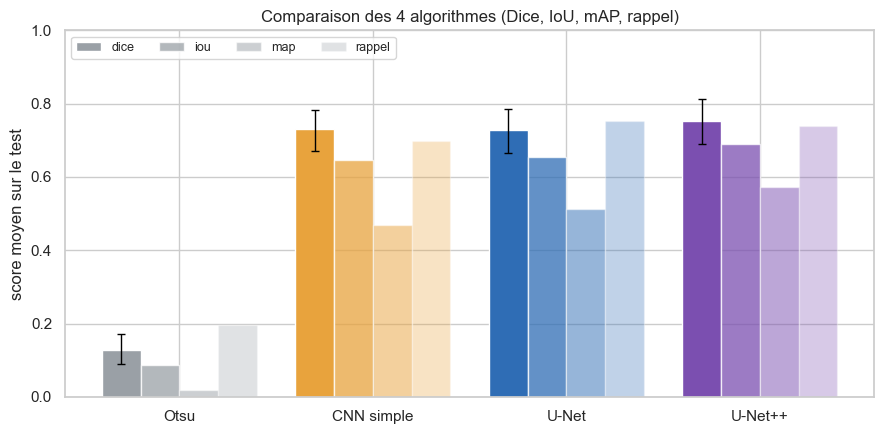

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
largeur = 0.2
x = np.arange(len(ORDRE))
for k, (metrique, alpha) in enumerate([("dice", 1.0), ("iou", 0.75), ("map", 0.5), ("rappel", 0.3)]):
    vals = tableau[metrique].values
    barres = ax.bar(x + (k - 1.5) * largeur, vals, largeur, label=metrique,
                    color=[COULEURS[m] for m in ORDRE], alpha=alpha, edgecolor="white")
    if metrique == "dice":
        err = np.abs(ic[["ic95_bas", "ic95_haut"]].values.T - ic["dice_moyen"].values)
        ax.errorbar(x + (k - 1.5) * largeur, vals, yerr=err, fmt="none", ecolor="black", capsize=3, lw=1)
ax.set_xticks(x, ORDRE)
ax.set_ylim(0, 1)
ax.set_ylabel("score moyen sur le test")
ax.set_title("Comparaison des 4 algorithmes (Dice, IoU, mAP, rappel)")
ax.legend(ncol=4, loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/04_comparaison_test.png", dpi=150)
plt.show()

### 6.2 Distribution du Dice image par image

Une moyenne cache beaucoup de choses. La boîte à moustaches montre la **dispersion** : la ligne centrale est la médiane, la boîte contient la moitié des images, et les points sont les images isolées. Un modèle avec beaucoup d'images à Dice = 0 rate complètement certaines tumeurs.

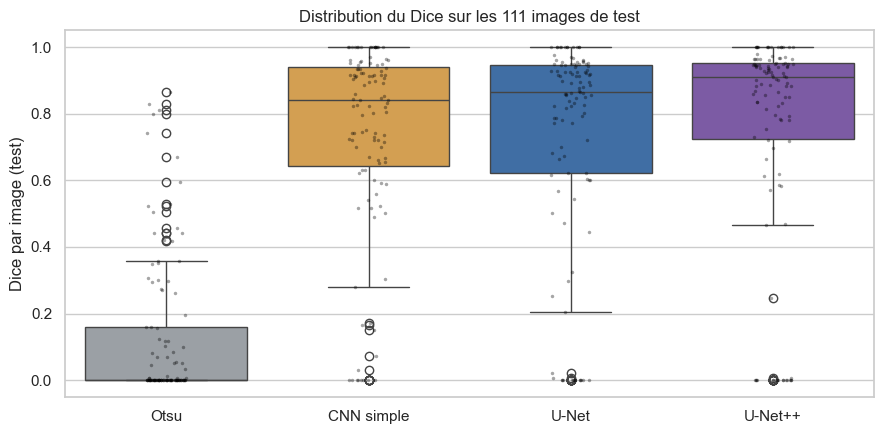

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=res_test, x="modele", y="dice", order=ORDRE, hue="modele", palette=COULEURS, legend=False, ax=ax)
sns.stripplot(data=res_test, x="modele", y="dice", order=ORDRE, color="black", size=2.5, alpha=0.35, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Dice par image (test)")
ax.set_title("Distribution du Dice sur les 111 images de test")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/04_distribution_dice.png", dpi=150)
plt.show()

### 6.3 Dice par classe

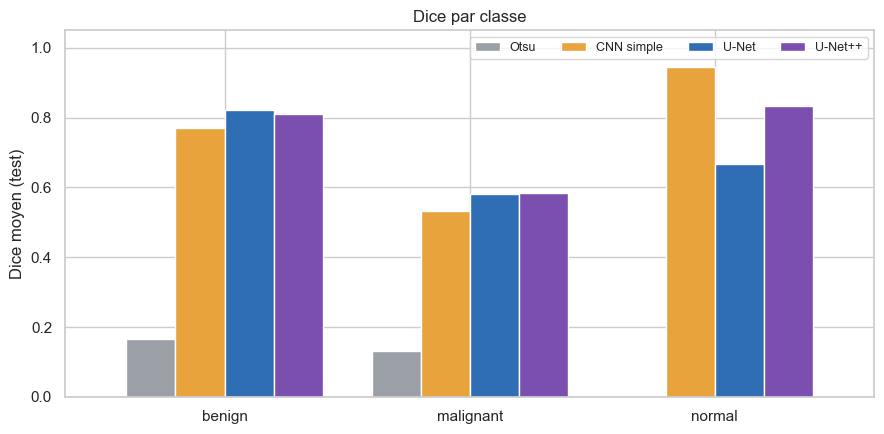

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5))
par_classe.T.plot(kind="bar", ax=ax, color=[COULEURS[m] for m in ORDRE], width=0.8, edgecolor="white")
ax.set_ylim(0, 1.05)
ax.set_xlabel("")
ax.set_ylabel("Dice moyen (test)")
ax.set_title("Dice par classe")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="", ncol=4, fontsize=9)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/04_dice_par_classe.png", dpi=150)
plt.show()

### 6.4 Le compromis précision / coût

Le choix d'un modèle à déployer ne dépend pas que du score : il compte aussi sa **vitesse** et sa **taille**. Chaque point est un algorithme ; sa taille représente le nombre de paramètres. L'idéal est **en haut à gauche** (bon et rapide).

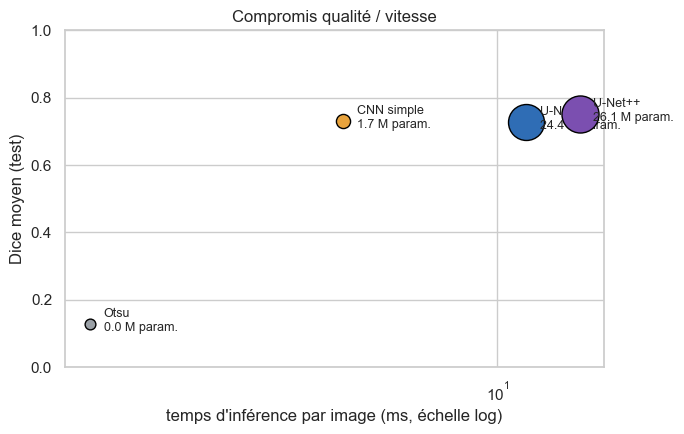

In [15]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for nom in ORDRE:
    taille_point = 60 + tableau.loc[nom, "parametres_M"] * 25
    ax.scatter(tableau.loc[nom, "inference_ms"], tableau.loc[nom, "dice"], s=taille_point,
               color=COULEURS[nom], edgecolor="black", zorder=3)
    ax.annotate(f"{nom}\n{tableau.loc[nom, 'parametres_M']:.1f} M param.",
                (tableau.loc[nom, "inference_ms"], tableau.loc[nom, "dice"]),
                textcoords="offset points", xytext=(10, -5), fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("temps d'inférence par image (ms, échelle log)")
ax.set_ylabel("Dice moyen (test)")
ax.set_ylim(0, 1)
ax.set_title("Compromis qualité / vitesse")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/04_compromis_vitesse.png", dpi=150)
plt.show()

### 6.5 Courbes d'apprentissage des configurations retenues

On relit les historiques enregistrés pendant l'entraînement (notebooks 02 et 03) pour les trois réseaux, dans leur meilleure configuration. On y vérifie l'absence de **surapprentissage** fort : si la perte d'entraînement baisse alors que celle de validation remonte, le modèle apprend « par cœur ». L'**arrêt anticipé** a gardé les poids de la meilleure époque de validation.

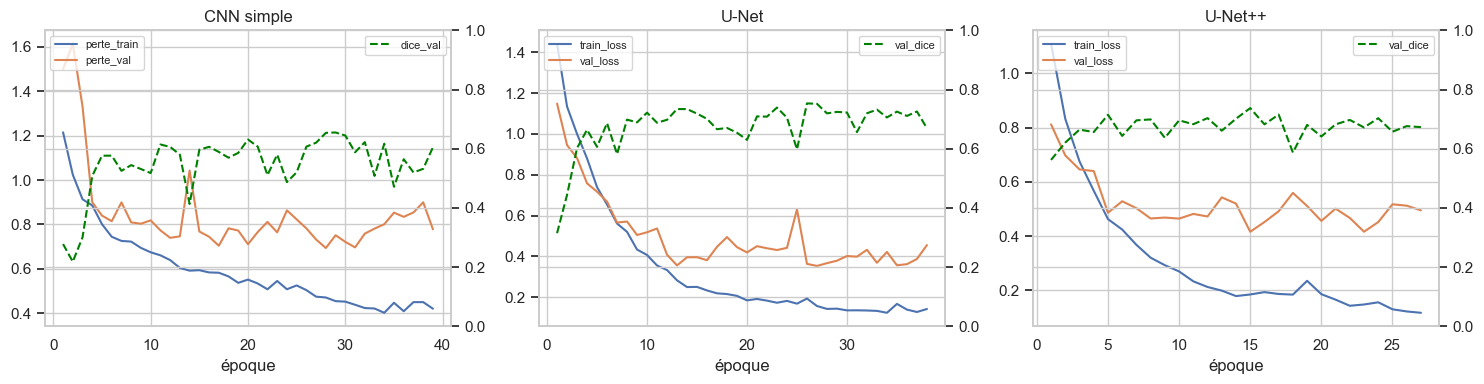

In [16]:
historiques = {
    "CNN simple": f"{OUT_DIR}/historique_cnn_{best_cnn['config']}.csv",
    "U-Net": f"{OUT_DIR}/historique_unet_{best_unet['perte']}_lr{best_unet['lr']:g}_{int(best_unet['taille'])}.csv",
    "U-Net++": f"{OUT_DIR}/historique_unetpp_{best_unetpp['perte']}_lr{best_unetpp['lr']:g}_{int(best_unetpp['taille'])}.csv",
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nom, chemin) in zip(axes, historiques.items()):
    if not os.path.exists(chemin):
        ax.set_title(f"{nom} : historique introuvable")
        continue
    h = pd.read_csv(chemin)
    x_ep = h[[c for c in h.columns if "epoque" in c.lower() or "epoch" in c.lower()][0]] \
        if any("epoque" in c.lower() or "epoch" in c.lower() for c in h.columns) else np.arange(1, len(h) + 1)
    for c in h.columns:
        if "perte" in c.lower() or "loss" in c.lower():
            ax.plot(x_ep, h[c], label=c, lw=1.5)
    ax2 = ax.twinx()
    for c in h.columns:
        if "dice" in c.lower():
            ax2.plot(x_ep, h[c], label=c, color="green", ls="--", lw=1.5)
    ax2.set_ylim(0, 1)
    ax.set_title(nom)
    ax.set_xlabel("époque")
    ax.legend(loc="upper left", fontsize=8)
    ax2.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/04_courbes_retenues.png", dpi=150)
plt.show()

---
## 7. Analyse des erreurs

Les scores moyens disent **combien** un modèle se trompe ; l'analyse d'erreurs cherche **quand** et **pourquoi**. On s'intéresse surtout au modèle retenu sur la validation, **U-Net**, et à sa comparaison avec U-Net++ (l'énoncé demande d'analyser les cas où les masques divergent).

### 7.1 Selon la taille de la tumeur

On répartit les images avec tumeur du test en **trois tiers** selon la part de l'image occupée par la tumeur (`ratio_tumeur`, calculé dans le notebook 01) : petites, moyennes, grandes.

Bornes des tiers (% de l'image occupée par la tumeur) :


,min,max
taille_tumeur,,
petites,0.48,4.83
moyennes,4.88,13.41
grandes,14.14,46.33


modele,Otsu,CNN simple,U-Net,U-Net++
taille_tumeur,,,,
petites,0.325,0.708,0.772,0.759
moyennes,0.112,0.732,0.739,0.758
grandes,0.023,0.632,0.712,0.690


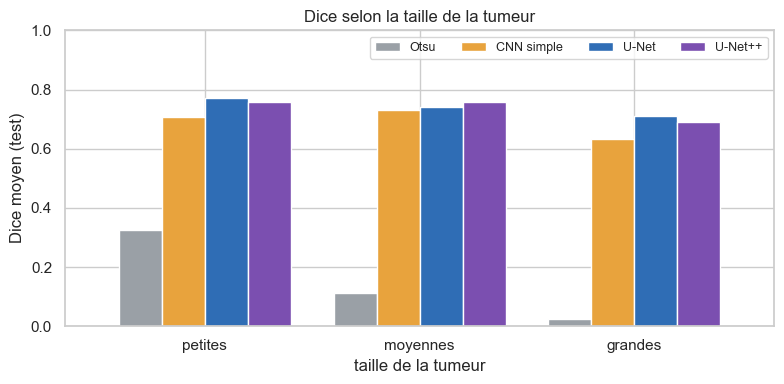

In [17]:
MODELE_RETENU = "U-Net"   # choisi sur la VALIDATION (notebooks 03), avant de voir le test

tumeurs = res_test[res_test["classe"] != "normal"].copy()
tumeurs["taille_tumeur"] = pd.qcut(tumeurs["ratio_tumeur"], 3, labels=["petites", "moyennes", "grandes"])

bornes = tumeurs.groupby("taille_tumeur", observed=True)["ratio_tumeur"].agg(["min", "max"]) * 100
print("Bornes des tiers (% de l'image occupée par la tumeur) :")
display(bornes.round(2))

par_taille = tumeurs.pivot_table(index="taille_tumeur", columns="modele", values="dice",
                                 aggfunc="mean", observed=True)[ORDRE]
display(par_taille.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
par_taille.plot(kind="bar", ax=ax, color=[COULEURS[m] for m in ORDRE], width=0.8, edgecolor="white")
ax.set_ylim(0, 1)
ax.set_xlabel("taille de la tumeur")
ax.set_ylabel("Dice moyen (test)")
ax.set_title("Dice selon la taille de la tumeur")
ax.tick_params(axis="x", rotation=0)
ax.legend(ncol=4, fontsize=9)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/04_dice_par_taille.png", dpi=150)
plt.show()

**Ce qu'on attend :** les **petites tumeurs** sont les plus difficiles. Quelques pixels d'écart sur le contour représentent une grande part de leur surface, et le passage à 256 × 256 efface une partie de leurs détails.

### 7.2 Les deux types d'erreurs graves

En clinique, toutes les erreurs n'ont pas la même gravité :

- **tumeur complètement manquée** : l'image a une tumeur, mais le modèle ne prédit **rien** ou prédit à côté (Dice = 0). C'est l'erreur la plus grave : une lésion passerait inaperçue ;
- **fausse alerte sur une image saine** : l'image est normale, mais le modèle signale une tumeur. C'est moins grave (le médecin vérifie), mais cela fait perdre du temps et de la confiance.

In [18]:
graves = pd.DataFrame({
    "tumeurs_manquees": tumeurs.groupby("modele")["dice"].apply(lambda d: (d == 0).sum()),
    "sur_n_tumeurs": tumeurs.groupby("modele").size(),
    "fausses_alertes_normales": res_test[res_test["classe"] == "normal"].groupby("modele")["dice"].apply(lambda d: (d == 0).sum()),
    "sur_n_normales": res_test[res_test["classe"] == "normal"].groupby("modele").size(),
}).reindex(ORDRE)
display(graves)

,tumeurs_manquees,sur_n_tumeurs,fausses_alertes_normales,sur_n_normales
modele,,,,
Otsu,44,93,18,18
CNN simple,7,93,1,18
U-Net,6,93,6,18
U-Net++,12,93,3,18


### 7.3 Les pires cas du modèle retenu

On affiche les **6 images avec tumeur** où U-Net obtient le plus mauvais Dice. Le contour **vert** est la vérité (radiologue), le contour **rouge** la prédiction.

En les regardant, on cherche des causes : tumeur très petite, contour flou, zone sombre voisine confondue avec la tumeur, image bruitée ou très contrastée, annotation discutable…

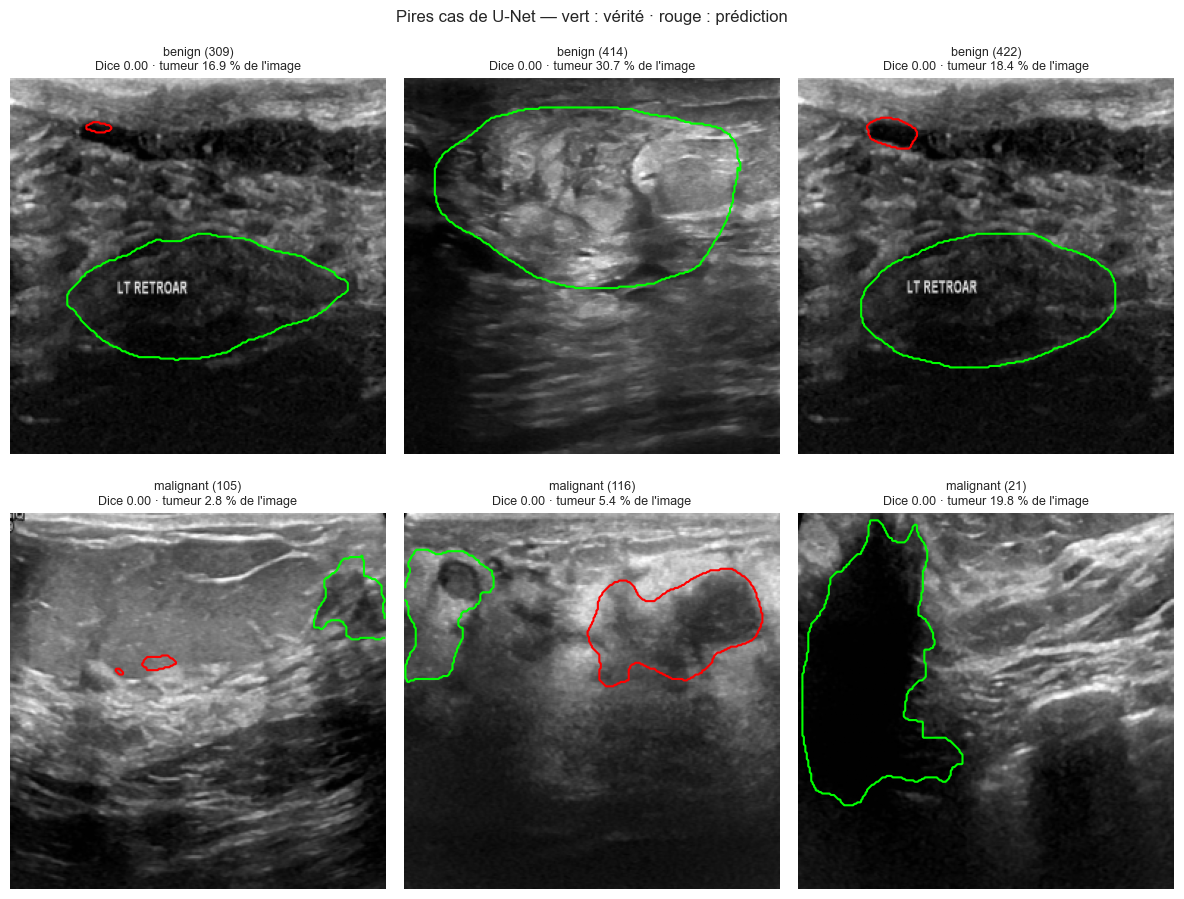

,id,classe,ratio_tumeur,dice,rappel,precision
253,benign (309),benign,0.169,0.0,0.0,0.0
269,benign (414),benign,0.307,0.0,0.0,0.0
271,benign (422),benign,0.184,0.0,0.0,0.0
284,malignant (105),malignant,0.028,0.0,0.0,0.0
287,malignant (116),malignant,0.054,0.0,0.0,0.0
304,malignant (21),malignant,0.198,0.0,0.0,0.0


In [19]:
def afficher_contours(ax, idx, probs_par_modele, titre):
    ax.imshow(X_test[idx], cmap="gray")
    ax.contour(Y_test[idx], levels=[0.5], colors="lime", linewidths=1.5)
    couleurs = ["red", "deepskyblue"]
    for (nom, probs), c in zip(probs_par_modele.items(), couleurs):
        if (probs[idx] > 0.5).any():
            ax.contour(probs[idx] > 0.5, levels=[0.5], colors=c, linewidths=1.5)
    ax.set_title(titre, fontsize=9)
    ax.axis("off")

position = {id_: k for k, id_ in enumerate(test_df["id"])}

pires = tumeurs[tumeurs["modele"] == MODELE_RETENU].nsmallest(6, "dice")
fig, axes = plt.subplots(2, 3, figsize=(12, 9.5))
for ax, (_, l) in zip(axes.ravel(), pires.iterrows()):
    afficher_contours(ax, position[l["id"]], {MODELE_RETENU: probs_test[MODELE_RETENU]},
                      f"{l['id']}\nDice {l['dice']:.2f} · tumeur {l['ratio_tumeur'] * 100:.1f} % de l'image")
fig.suptitle(f"Pires cas de {MODELE_RETENU} — vert : vérité · rouge : prédiction", fontsize=12)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/04_pires_cas_{MODELE_RETENU}.png", dpi=150)
plt.show()

display(pires[["id", "classe", "ratio_tumeur", "dice", "rappel", "precision"]].round(3))

### 7.4 Les cas où U-Net et U-Net++ divergent

L'énoncé demande d'analyser les **cas où les masques divergent**. On classe les images selon l'écart de Dice entre les deux modèles et on affiche les 6 plus grands écarts, dans les deux sens.

Contour **vert** : vérité · **rouge** : U-Net · **bleu** : U-Net++.

Ces cas montrent ce que les **skip connections denses** d'U-Net++ changent concrètement : contours plus fins, ou au contraire zones parasites, sur quelles images.

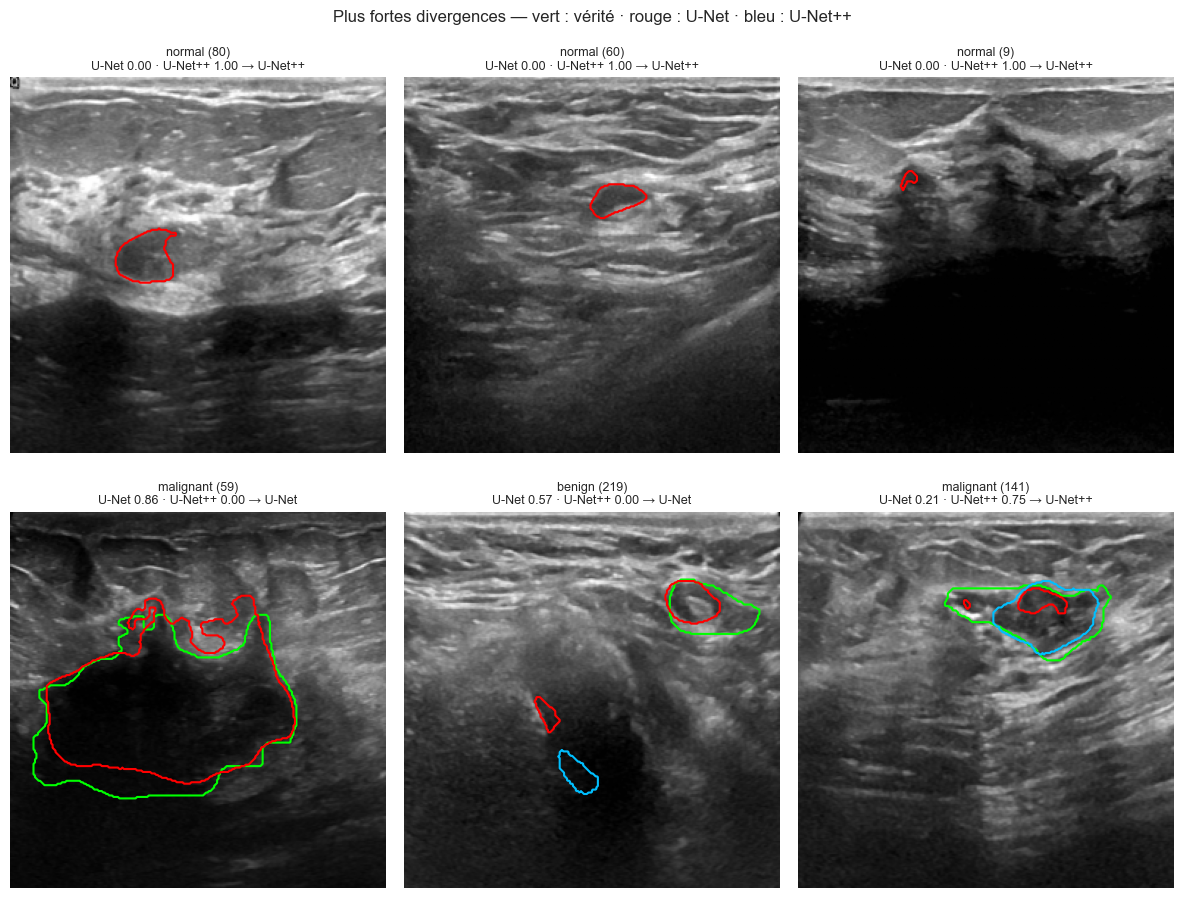

U-Net meilleur sur 15 images, U-Net++ meilleur sur 27, quasi-égalité (écart ≤ 0,05) sur 69 images.


In [20]:
ecart = (dice_par_image["U-Net"] - dice_par_image["U-Net++"]).rename("ecart")
divergences = ecart.reindex(ecart.abs().sort_values(ascending=False).index).head(6)

fig, axes = plt.subplots(2, 3, figsize=(12, 9.5))
for ax, (id_, d) in zip(axes.ravel(), divergences.items()):
    gagnant = "U-Net" if d > 0 else "U-Net++"
    afficher_contours(ax, position[id_], {"U-Net": probs_test["U-Net"], "U-Net++": probs_test["U-Net++"]},
                      f"{id_}\nU-Net {dice_par_image.loc[id_, 'U-Net']:.2f} · "
                      f"U-Net++ {dice_par_image.loc[id_, 'U-Net++']:.2f} → {gagnant}")
fig.suptitle("Plus fortes divergences — vert : vérité · rouge : U-Net · bleu : U-Net++", fontsize=12)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/04_divergences_unet_unetpp.png", dpi=150)
plt.show()

print(f"U-Net meilleur sur {(ecart > 0.05).sum()} images, U-Net++ meilleur sur {(ecart < -0.05).sum()}, "
      f"quasi-égalité (écart ≤ 0,05) sur {(ecart.abs() <= 0.05).sum()} images.")

### 7.5 Pourquoi Otsu échoue

Pour illustrer l'intérêt du deep learning, on compare les 4 algorithmes sur **la même image** : une image où U-Net réussit bien. Otsu ne fait que séparer le **sombre** du **clair** : il colorie aussi les ombres, les tissus sombres et les zones sous la tumeur, sans « comprendre » la forme d'une lésion.

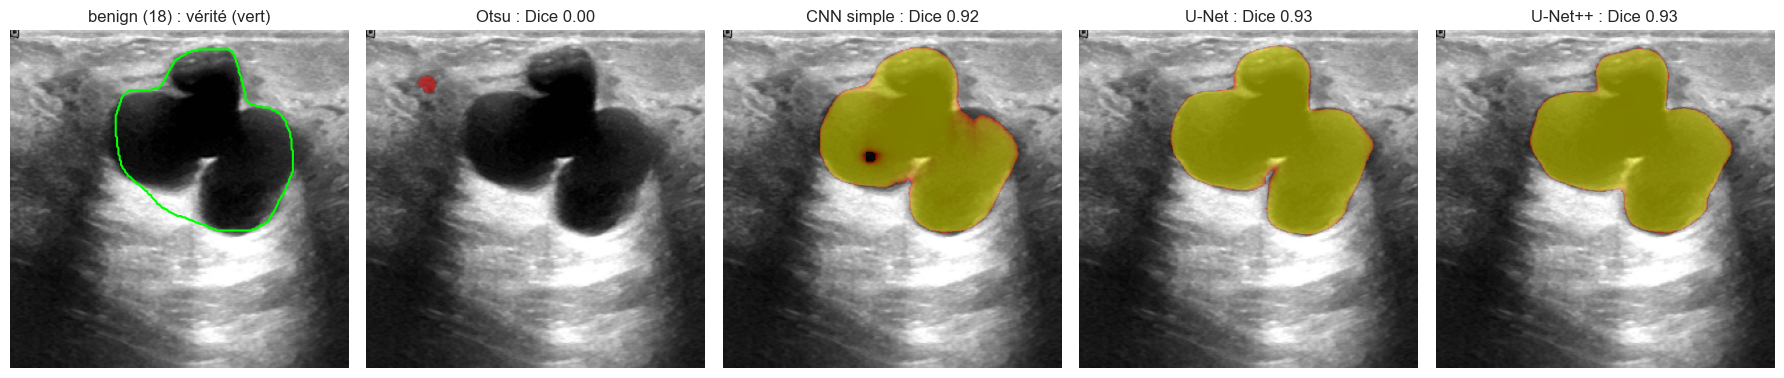

In [21]:
# une image où U-Net réussit bien (au quart supérieur des Dice, pas forcément la meilleure)
reussites = tumeurs[tumeurs["modele"] == MODELE_RETENU].sort_values("dice", ascending=False)
exemple = reussites.iloc[len(reussites) // 4]
idx = position[exemple["id"]]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
axes[0].imshow(X_test[idx], cmap="gray")
axes[0].contour(Y_test[idx], levels=[0.5], colors="lime", linewidths=1.5)
axes[0].set_title(f"{exemple['id']} : vérité (vert)")
axes[0].axis("off")
for ax, nom in zip(axes[1:], ORDRE):
    ax.imshow(X_test[idx], cmap="gray")
    ax.imshow(np.ma.masked_where(probs_test[nom][idx] <= 0.5, probs_test[nom][idx]), cmap="autumn", alpha=0.5)
    ax.set_title(f"{nom} : Dice {dice_par_image.loc[exemple['id'], nom]:.2f}")
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/04_meme_image_4_algos.png", dpi=150)
plt.show()

---
## 8. Conclusion et choix du modèle

La cellule suivante résume automatiquement les chiffres clés du test. Le texte de conclusion qui suit est à **compléter avec ces chiffres** une fois le notebook exécuté.

In [22]:
r = tableau.round(3)
print("=== Résultats sur le test (111 images, jamais vues avant ce notebook) ===\n")
for nom in ORDRE:
    print(f"{nom:10s} Dice {r.loc[nom, 'dice']:.3f}  [IC95 {ic.loc[nom, 'ic95_bas']:.3f} – {ic.loc[nom, 'ic95_haut']:.3f}]"
          f"  IoU {r.loc[nom, 'iou']:.3f}  mAP {r.loc[nom, 'map']:.3f}  rappel {r.loc[nom, 'rappel']:.3f}"
          f"  {r.loc[nom, 'inference_ms']:.1f} ms/image")

d = dice_par_image["U-Net"] - dice_par_image["U-Net++"]
bas, haut = ic_bootstrap(d)
print(f"\nÉcart U-Net − U-Net++ : {d.mean():+.3f} [IC95 {bas:+.3f} ; {haut:+.3f}]",
      "→ pas de différence démontrée" if bas <= 0 <= haut else "→ écart significatif")
print(f"Modèle retenu (choisi sur la validation) : {MODELE_RETENU}")

=== Résultats sur le test (111 images, jamais vues avant ce notebook) ===

Otsu       Dice 0.129  [IC95 0.091 – 0.172]  IoU 0.088  mAP 0.020  rappel 0.195  1.4 ms/image
CNN simple Dice 0.732  [IC95 0.671 – 0.784]  IoU 0.647  mAP 0.470  rappel 0.697  4.8 ms/image
U-Net      Dice 0.729  [IC95 0.665 – 0.787]  IoU 0.653  mAP 0.514  rappel 0.752  11.5 ms/image
U-Net++    Dice 0.752  [IC95 0.690 – 0.813]  IoU 0.689  mAP 0.574  rappel 0.740  14.8 ms/image

Écart U-Net − U-Net++ : -0.023 [IC95 -0.065 ; +0.017] → pas de différence démontrée
Modèle retenu (choisi sur la validation) : U-Net


### Synthèse (à compléter avec les chiffres ci-dessus)

**1. Le deep learning est nécessaire.** Otsu plafonne à un Dice d'environ **[X]** : il sépare le sombre du clair sans reconnaître la forme d'une tumeur. Le CNN simple atteint **[X]**, puis U-Net et U-Net++ **[X]** et **[X]**.

**2. Les skip connections et l'encodeur pré-entraîné apportent un vrai gain.** Entre le CNN simple (sans skip connections, entraîné de zéro) et U-Net, le Dice gagne **[X]** points et le rappel passe de **[X]** à **[X]** : les contours sont plus précis et moins de tumeurs sont manquées.

**3. U-Net++ n'apporte pas de gain démontré sur BUSI.** L'écart avec U-Net est de **[X]**, avec un intervalle de confiance qui **[contient / ne contient pas]** 0. Il compte **[X] M** de paramètres en plus et s'entraîne plus lentement. Sur un dataset aussi petit (762 images), la complexité supplémentaire de ses skip connections denses n'a pas assez d'exemples pour être exploitée.

**4. Les erreurs restantes** concernent surtout **[les petites tumeurs / les tumeurs malignes aux contours irréguliers / …]** (Dice **[X]** sur le tiers des plus petites tumeurs). U-Net manque complètement **[X]** tumeurs sur **[X]** et signale **[X]** fausses alertes sur **[X]** images saines.

**5. Choix retenu pour la suite : U-Net (ResNet34, BCE+Dice, lr 1e-4, 256 × 256).**
Il a été choisi **sur la validation**, avant de voir le test, et le test confirme ce choix : il est **au moins aussi bon** qu'U-Net++, plus **simple**, plus **léger** et plus **rapide** (environ **[X] ms** par image), ce qui convient à un service d'inférence FastAPI utilisé en temps réel.

### Limites

- **Pas d'identifiant patient** dans BUSI : le découpage par groupe de quasi-doublons est la meilleure approximation possible d'un découpage par patient.
- **Petit test** (111 images, dont 31 malignes et 18 normales) : les résultats par classe ont de larges intervalles de confiance.
- **Un seul entraînement par configuration** : les scores varient d'un entraînement à l'autre ; plusieurs graines aléatoires auraient permis de mesurer cette variabilité.
- **Seuil fixé à 0,5** : il n'a pas été réglé ; un seuil plus bas augmenterait le rappel au prix de la précision.